In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


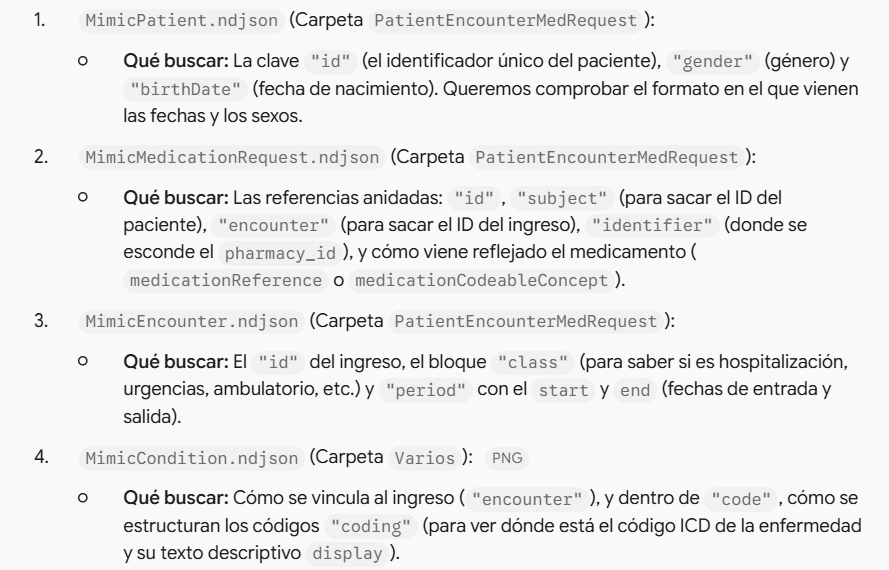

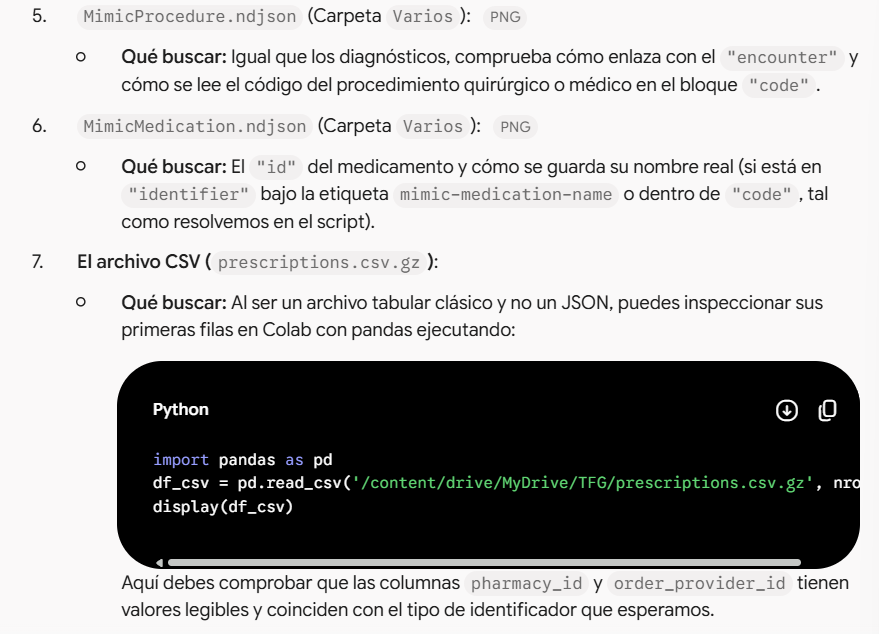

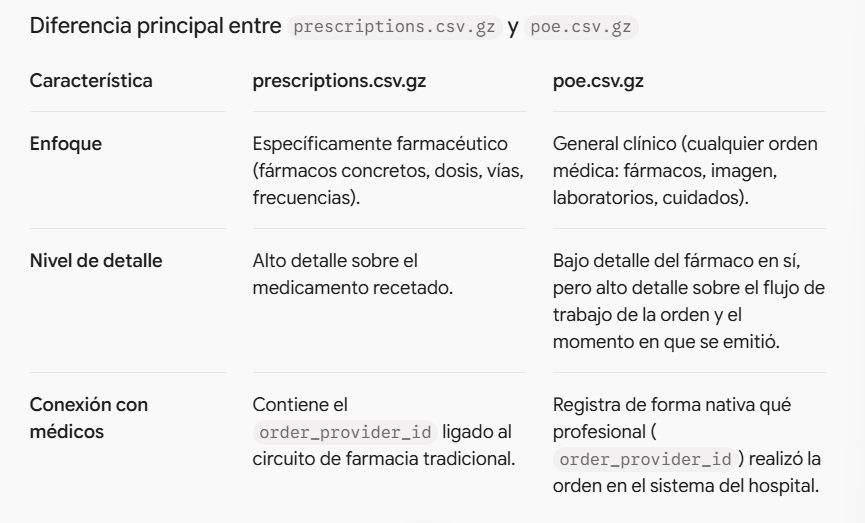

# SCRIPT PARA INSPECCIONAR LOS ndjson

In [ ]:
import json
import os

def ver_muestra_drive(ruta_archivo, num_lineas=5):
    if not os.path.exists(ruta_archivo):
        print(f"❌ No se encuentra el archivo en: {ruta_archivo}")
        return

    print(f"🔍 Mostrando las primeras {num_lineas} líneas de: {os.path.basename(ruta_archivo)}\n")
    print("-" * 60)

    with open(ruta_archivo, 'rt', encoding='utf-8', errors='ignore') as f:
        for i in range(num_lineas):
            linea = f.readline()
            if not linea:
                break
            try:
                datos = json.loads(linea.strip())
                print(f"Línea {i + 1}:")
                print(json.dumps(datos, indent=4, ensure_ascii=False))
            except json.JSONDecodeError:
                print(f"Línea {i + 1} (Texto plano/Error de JSON): {linea.strip()}")
            print("-" * 60)

# EJEMPLO DE USO:
archivo_a_mirar = os.path.join('/content/drive/MyDrive/TFG/PatientEncounterMedRequest', 'MimicMedicationRequest.ndjson')
ver_muestra_drive(archivo_a_mirar, num_lineas=3)

🔍 Mostrando las primeras 3 líneas de: MimicMedicationRequest.ndjson

------------------------------------------------------------
Línea 1:
{
    "id": "d464da3e-3945-574a-b2bc-5ebba85c2e58",
    "meta": {
        "profile": [
            "http://mimic.mit.edu/fhir/mimic/StructureDefinition/mimic-medication-request"
        ]
    },
    "intent": "order",
    "status": "completed",
    "subject": {
        "reference": "Patient/00000027-c5e0-554f-8e85-b097c3b177d4"
    },
    "encounter": {
        "reference": "Encounter/c8816dcb-47f0-55f0-933f-122d0caac629"
    },
    "authoredOn": "2140-01-05T18:40:51-05:00",
    "identifier": [
        {
            "value": "5432712",
            "system": "http://mimic.mit.edu/fhir/mimic/identifier/medication-request-phid"
        }
    ],
    "resourceType": "MedicationRequest",
    "dispenseRequest": {
        "validityPeriod": {
            "end": "2140-01-06T10:00:00-05:00",
            "start": "2140-01-05T10:00:00-05:00"
        }
    },
   

#SCRIPT PARA INSPECCIONAR LOS csv

In [ ]:
import pandas as pd
import os

# Ajusta esta ruta si lo tienes en otra subcarpeta de tu Drive
BASE_DRIVE = '/content/drive/MyDrive/TFG'
ruta_poe = os.path.join(BASE_DRIVE, 'poe.csv.gz')

if os.path.exists(ruta_poe):
    print("🔍 Inspeccionando las primeras 5 filas de poe.csv.gz:\n")
    df_poe = pd.read_csv(ruta_poe, nrows=5)
    print(df_poe.columns.tolist())
    display(df_poe)
else:
    print(f"⚠️ No se encuentra el archivo poe.csv.gz en la ruta: {ruta_poe}. Súbelo para poder examinarlo.")

🔍 Inspeccionando las primeras 5 filas de poe.csv.gz:

['poe_id', 'poe_seq', 'subject_id', 'hadm_id', 'ordertime', 'order_type', 'order_subtype', 'transaction_type', 'discontinue_of_poe_id', 'discontinued_by_poe_id', 'order_provider_id', 'order_status']


,poe_id,poe_seq,subject_id,hadm_id,ordertime,order_type,order_subtype,transaction_type,discontinue_of_poe_id,discontinued_by_poe_id,order_provider_id,order_status
0,10000032-100,100,10000032,22841357,2180-06-26 22:09:02,Medications,NaN,New,NaN,NaN,P992IN,Inactive
1,10000032-101,101,10000032,22841357,2180-06-26 22:09:02,General Care,Code status,New,NaN,NaN,P992IN,Inactive
2,10000032-102,102,10000032,22841357,2180-06-26 22:09:02,Nutrition,Nutrition consult,New,NaN,NaN,P992IN,Inactive
3,10000032-103,103,10000032,22841357,2180-06-26 22:09:02,Blood Bank,Blood tests,New,NaN,NaN,P992IN,Inactive
4,10000032-104,104,10000032,22841357,2180-06-26 22:09:02,Lab,NaN,New,NaN,NaN,P992IN,Inactive


In [ ]:
import pandas as pd
import os

# Rutas en tu Google Drive
BASE_DRIVE = '/content/drive/MyDrive/TFG'
ruta_poe = os.path.join(BASE_DRIVE, 'poe.csv.gz')

if os.path.exists(ruta_poe):
    print("⏳ Cargando y filtrando poe.csv.gz (solo órdenes de medicamentos)...")

    # Leemos el CSV optimizando memoria y filtrando solo las de tipo Medications
    # (Usamos chunksize o lectura directa según el tamaño, vamos a leer las primeras 100k filas para la prueba piloto)
    df_poe = pd.read_csv(ruta_poe, nrows=100000, dtype=str)

    # Filtramos solo las órdenes de medicamentos que tengan un médico asignado
    df_poe_meds = df_poe[(df_poe['order_type'] == 'Medications') & (df_poe['order_provider_id'].notna())]

    print(f"✅ ¡Carga de prueba completada!")
    print(f"   - Órdenes de medicamentos encontradas en la muestra: {len(df_poe_meds)}")
    print("\nEjemplo de registros en poe.csv.gz filtrados por medicamentos:")
    display(df_poe_meds[['poe_id', 'subject_id', 'hadm_id', 'ordertime', 'order_provider_id']].head(5))
else:
    print(f"⚠️ No se encuentra el archivo poe.csv.gz en: {ruta_poe}")

⏳ Cargando y filtrando poe.csv.gz (solo órdenes de medicamentos)...
✅ ¡Carga de prueba completada!
   - Órdenes de medicamentos encontradas en la muestra: 44511

Ejemplo de registros en poe.csv.gz filtrados por medicamentos:


,poe_id,subject_id,hadm_id,ordertime,order_provider_id
0,10000032-100,10000032,22841357,2180-06-26 22:09:02,P992IN
6,10000032-107,10000032,22841357,2180-06-26 22:37:06,P992IN
7,10000032-108,10000032,22841357,2180-06-26 22:37:06,P992IN
11,10000032-113,10000032,22841357,2180-06-27 17:05:25,P87CLZ
23,10000032-125,10000032,29079034,2180-07-23 07:14:52,P406KF
